# 01 · Forecast contract, availability and data audit
## Summary
This notebook fixes the research contract before model comparison, preserves raw inputs, produces the data dictionary and availability register, and reports defects without interpolating targets or deleting peaks. Read the computed audit and gate below before interpreting later scores.

The original conversational notebook is preserved in `notebooks/legacy/01_data_audit_original.ipynb`.
## Context and methods
The operational information cutoff is **11:00 Europe/Paris on D−1**; delivery is the complete next local day. Two-hour publication delay after interval end is an **assumption**, not measured metadata. The recent chronological test spans **2025-07-01 through 2026-06-30**. Earlier EDA already inspected it: it is not a pristine holdout.
### Key assumptions
Hourly interval-start labels, mean power and final observation vintages are unverified. Daily MWh and all historical replays are conditional on these approximations. Candidate weather runs are not fabricated from realized weather.

In [1]:
%matplotlib inline
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "config/forecast_contract.json").exists())
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
from src.common import load_contract, prepare_directories, plotting_style, write_json, fingerprint
contract = load_contract(ROOT)
prepare_directories(ROOT)
plotting_style()
pd.set_option("display.max_columns", 12)
pd.set_option("display.max_rows", 16)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

### 1. Freeze the contract and source identities

In [2]:
from src.data import run_audit, availability_gate
lock_path = ROOT / "config/evaluation_lock.json"
identity = {"contract_sha256": fingerprint(ROOT/"config/forecast_contract.json"), "country_sha256": fingerprint(ROOT/"data/france_electricity_hourly.csv"), "regional_sha256": fingerprint(ROOT/"data/france_regional_electricity_hourly.csv")}
if lock_path.exists() and json.loads(lock_path.read_text()) != identity:
    raise RuntimeError("Contract or source changed after freeze. Preserve the old run and explicitly create a new experiment/lock before rerunning.")
write_json(lock_path, identity)
display(pd.Series(contract, name="contract").to_frame())

,contract
version,1.0.0
frozen_on,2026-10-20
timezone,Europe/Paris
origin_hour_local,11
origin_minute_local,0
...,...
quantiles,"[0.05, 0.5, 0.95]"
bootstrap_block_days,"[7, 14, 28]"
bootstrap_repetitions,500
minimum_improvement_percent,0


### 2. Audit without modifying raw values

In [3]:
data, dictionary, audit = run_audit(ROOT, contract)
display(pd.Series(audit, name="audit_result").to_frame())
display(dictionary[["dataset","field","unit","definition","missing","operational_before_cutoff"]])
display(pd.read_csv(ROOT/"reports/audit/availability_register.csv"))

,audit_result
country_rows,65710
regional_rows,367752
regions,12
country_duplicate_keys,0
regional_duplicate_keys,0
hourly_grid_missing_rows,0
country_target_missing,7
rte_missing,7
weather_missing,0
complete_regional_overlap_hours,30643


,dataset,field,unit,definition,missing,operational_before_cutoff
0,country,datetime_utc,timestamp,delivery interval start ASSUMED,0,unverified
1,country,load_mw,MW,consumption power; hourly averaging unverified,7,unverified
2,country,rte_forecast_d1_mw,MW,provided day-ahead forecast; cutoff version un...,7,unverified
3,country,temperature_c,degree C,temperature; aggregation and observed/forecast...,0,unverified
4,regional,region,category,administrative region,0,unverified
5,regional,datetime_utc,timestamp,delivery interval start ASSUMED,0,unverified
6,regional,load_mw,MW,consumption power; hourly averaging unverified,36,unverified
7,regional,temperature_c,degree C,temperature; aggregation and observed/forecast...,0,unverified


,dataset,field,issued_at,available_at,revision_status,retrospective_assumption,operational_before_cutoff
0,country,datetime_utc,not supplied,not supplied,unknown,interval end + 2 hours for observed history; R...,unverified
1,country,load_mw,not supplied,not supplied,unknown,interval end + 2 hours for observed history; R...,unverified
2,country,rte_forecast_d1_mw,not supplied,not supplied,unknown,interval end + 2 hours for observed history; R...,unverified
3,country,temperature_c,not supplied,not supplied,unknown,interval end + 2 hours for observed history; R...,unverified
4,regional,region,not supplied,not supplied,unknown,interval end + 2 hours for observed history; R...,unverified
5,regional,datetime_utc,not supplied,not supplied,unknown,interval end + 2 hours for observed history; R...,unverified
6,regional,load_mw,not supplied,not supplied,unknown,interval end + 2 hours for observed history; R...,unverified
7,regional,temperature_c,not supplied,not supplied,unknown,interval end + 2 hours for observed history; R...,unverified


### 3. Missingness, frequency and population overlap

,field,missing_count,missing_fraction
0,load_mw,7,0.000
1,rte_forecast_d1_mw,7,0.000
8,regional_load_mw,35067,0.534
9,regional_temperature_mean_c,35064,0.534
10,n_regions,35064,0.534
11,n_loads,35064,0.534
12,n_temperatures,35064,0.534
13,regional_temperature_load_weighted_c,35067,0.534
14,load_country_minus_regions_mw,35067,0.534


,interval,count
0,0 days 01:00:00,65709


,country_present,rte_present,weather_present,regional_present,hours
0,True,False,True,False,4
1,True,False,True,True,3
2,True,True,True,False,35060
3,True,True,True,True,30643


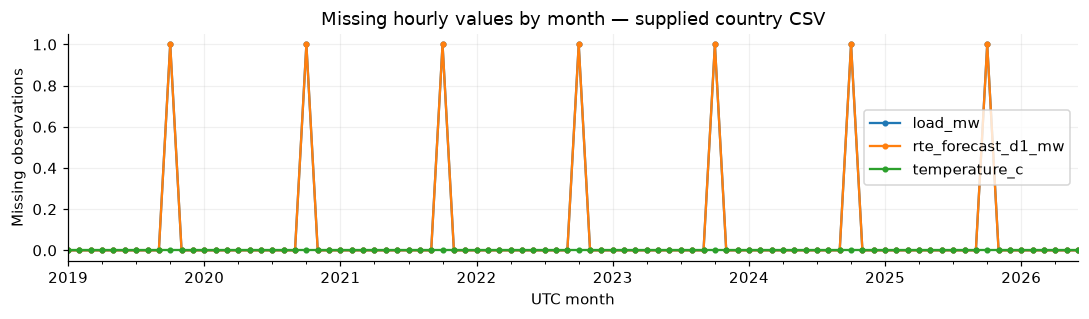

In [4]:
display(pd.read_csv(ROOT/"reports/audit/missingness.csv").rename(columns={"Unnamed: 0":"field"}).query("missing_count > 0"))
display(pd.read_csv(ROOT/"reports/audit/frequency_intervals.csv"))
display(pd.read_csv(ROOT/"reports/audit/overlap.csv"))
fig, ax = plt.subplots(figsize=(10,3))
monthly_missing = data[["load_mw","rte_forecast_d1_mw","temperature_c"]].isna().resample("MS").sum()
monthly_missing.plot(ax=ax, marker=".")
ax.set(title="Missing hourly values by month — supplied country CSV", ylabel="Missing observations", xlabel="UTC month")
plt.tight_layout(); plt.show()

### 4. Reconcile national and regional measurements

,country_minus_regions_MW
count,"30,643.000"
mean,-0.045
std,9.370
min,"-1,620.000"
25%,-1.000
50%,0.000
75%,1.000
max,6.000


,load_mw,regional_load_mw,load_country_minus_regions_mw
datetime_utc,,,
2025-11-13 11:00:00+00:00,"55,340.000","56,960.000","-1,620.000"


,hours,bias_C,MAE_C,RMSE_C
regional_temperature_mean_c,30643,0.112,0.442,0.580
regional_temperature_load_weighted_c,30643,0.057,0.421,0.550


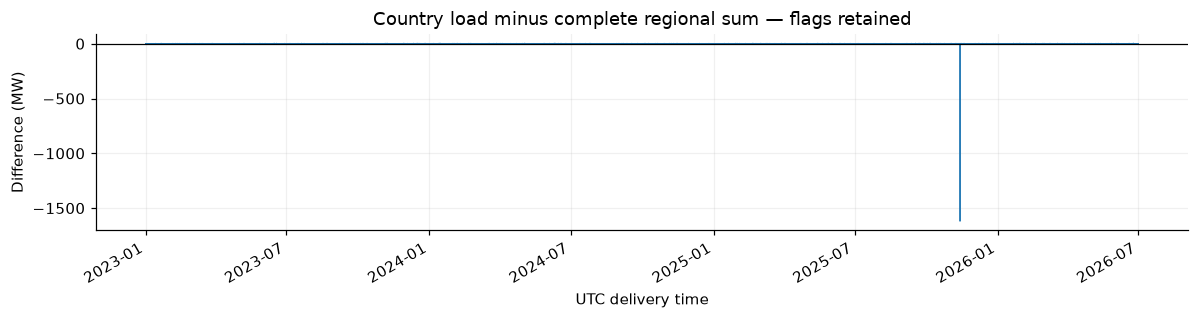

In [5]:
delta = data.load_country_minus_regions_mw.dropna()
display(delta.describe().to_frame("country_minus_regions_MW"))
flagged = data.loc[data.reconciliation_flag, ["load_mw","regional_load_mw","load_country_minus_regions_mw"]]
display(flagged)
temperature = data[["temperature_c","regional_temperature_mean_c","regional_temperature_load_weighted_c"]].dropna()
errors = temperature.iloc[:,1:].rsub(temperature.temperature_c,axis=0)
display(pd.DataFrame({"hours":errors.count(),"bias_C":errors.mean(),"MAE_C":errors.abs().mean(),"RMSE_C":np.sqrt(errors.pow(2).mean())}))
fig, ax = plt.subplots(figsize=(11,3))
delta.plot(ax=ax, linewidth=.6)
ax.axhline(0,color="black",linewidth=.8)
ax.set(title="Country load minus complete regional sum — flags retained",ylabel="Difference (MW)",xlabel="UTC delivery time")
plt.tight_layout(); plt.show()

### 5. Operational gate and source conversion limitations

In [6]:
gate = availability_gate(ROOT, contract)
display(gate)
display(Markdown((ROOT/"reports/audit/limitations.md").read_text()))
assert data.load_mw.isna().sum() == audit["country_target_missing"]
assert audit["no_targets_interpolated"] and audit["peaks_deleted"] == 0
print("Audited rows:",len(data),"; operational experiment enabled:",bool(gate.operational_experiment_enabled.all()))

,source,nonempty_archive_with_schema,provenance_verified,operationally_usable,rows,interval_aggregation_verified,operational_experiment_enabled
0,demand,False,False,False,0,False,False
1,rte,False,False,False,0,False,False
2,weather,False,False,False,0,False,False


# Limitations

- Supplied CSV provenance, hourly averaging, interval labels, and revision vintages are unverified. Interval-start labels and one-hour mean-power values are explicit assumptions. Daily MWh is conditional on these assumptions.
- The RTE documentation describes quarter-hourly source values and subsequent consolidation/definitive revisions. No source-to-hourly conversion recipe was provided; matching timestamps do not prove matching intervals.
- No trustworthy archived RTE forecast issues, weather runs, or original demand observation vintages were supplied. Original observation availability is approximated as interval end plus two hours in retrospective runs only.
- Provided RTE values are an explicitly assumed-cutoff retrospective benchmark. Recorded future temperature is restricted to separately named oracle sensitivity experiments. No operational superiority is established.
- Earlier conversation and legacy EDA inspected the full history. The chronological test period is previously exposed, not pristine. Freezing this implementation now cannot undo that exposure; fresh prospective evaluation is required.
- Missing targets remain missing and are counted. Peaks and the country/regional discrepancy are retained and flagged; source verification is needed before correction.
- National consumption is a utility portfolio proxy. National public holidays omit school holidays and local exceptions. No customer portfolio, price, settlement or procurement data are provided.
- Forecast skill and shortage/surplus energy proxies are not euro savings. Hourly forecasting does not implement quarter-hour market or settlement alignment.


Audited rows: 65710 ; operational experiment enabled: False


## Takeaways and deliverables
Outputs: audited hourly grid in `data/processed/`; dictionary, register, frequency/overlap/missingness tables and limitations in `reports/audit/`; checksummed source manifest in `data/raw/`.

No source-to-hourly transformation can be verified from these CSVs alone. Obtain the extraction script, interval convention, original observation revisions and issued forecast archives before changing the operational gate.

Sources: [ODRÉ revisions and source cadence](https://odre.opendatasoft.com/explore/dataset/eco2mix-national-tr/), [RTE demand and forecast definitions](https://www.rte-france.com/donnees-publications/eco2mix-donnees-temps-reel/consommation-france).
Next: development-only EDA.